# M507 Methods of Prediction – Individual Project
## Project Title: Face Liveness Detection for Secure Attendance Systems

**Student:** Deepak Sindhu 
**Dataset:** OULU-NPU Face Anti-Spoofing Dataset  
**Link:** https://www.kaggle.com/datasets/mizaku/oulu-npu-test

In [7]:
# Basic imports
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    roc_auc_score, accuracy_score, precision_score, recall_score
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, Model, callbacks
from tensorflow.keras.optimizers import Adam

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

print("TensorFlow version:", tf.__version__)

TensorFlow: 2.21.0
TensorFlow version: 2.21.0



## 1. Problem Statement

Face-based attendance systems can be tricked using printed photos or videos of another person. This may lead to incorrect attendance records and security problems.

The aim of this project is to develop a deep learning model that classifies face images as Fake or Real. MobileNetV2 is used to learn image patterns and make predictions.

This model could support the security of an attendance system. However, it only classifies images and does not verify a person's identity. Further testing is needed before it can be used in a real workplace.

# 2. Data Exploration

The dataset contains training, validation, and test images. The training set is used to train the model, the validation set is used to compare model configurations, and the test set is used for final evaluation.

The dataset contains 1,701 images: 1,358 Fake images and 343 Real images. This means that approximately 79.8% are Fake and 20.2% are Real. Therefore, the dataset has a class imbalance, with fewer Real images available for training.

Accuracy alone may not show how well the model performs on both classes. For this reason, macro-F1 is used for model selection, while precision, recall, and ROC-AUC provide additional information about performance.

,split,class,images
0,train,false,888
1,train,true,216
2,val,false,230
3,val,true,54
4,test,false,240
5,test,true,73


,split,images,percentage_of_all_images
0,test,313,18.4
1,train,1104,64.9
2,val,284,16.7


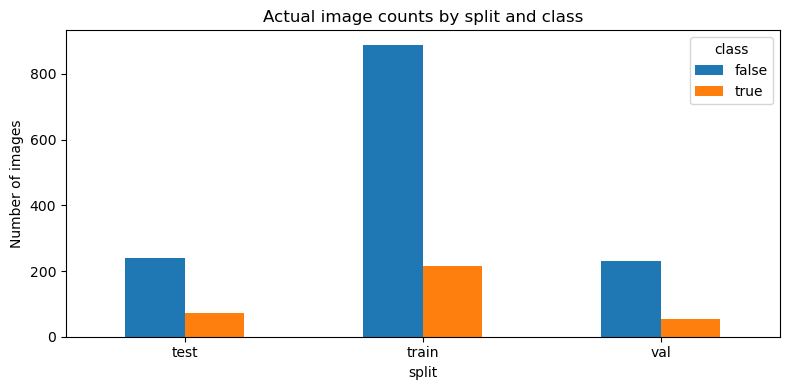

In [8]:
from pathlib import Path

base_dir = r"F:\methods of prediction\assignment\Oulu-NPU"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images_in_split(split_path):
    rows = []
    split_path = Path(split_path)
    if not split_path.exists():
        raise FileNotFoundError(f"Folder not found: {split_path}")
    for class_dir in sorted(p for p in split_path.iterdir() if p.is_dir()):
        count = sum(1 for p in class_dir.rglob("*")
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        rows.append({"split": split_path.name, "class": class_dir.name, "images": count})
    return rows

count_rows = []
for split in ["train", "val", "test"]:
    count_rows.extend(count_images_in_split(Path(base_dir) / split))

counts_df = pd.DataFrame(count_rows)
display(counts_df)

if counts_df.empty or (counts_df["images"] == 0).any():
    print("Check the directory names and image files before continuing.")

split_totals = counts_df.groupby("split", as_index=False)["images"].sum()
split_totals["percentage_of_all_images"] = (
    100 * split_totals["images"] / split_totals["images"].sum()
).round(2)
display(split_totals)

class_distribution = counts_df.pivot(index="split", columns="class", values="images").fillna(0)
class_distribution.plot(kind="bar", figsize=(8, 4))
plt.title("Actual image counts by split and class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Result Interpretation: Image Counts**

The training set contains 1,104 images, the validation set contains 284 images, and the test set contains 313 images. The split is approximately 64.9% training, 16.7% validation, and 18.4% test.

The higher number of Fake images may affect model performance. Class weighting was therefore tested in some experiments. The available counts do not confirm whether the same subjects or near-duplicate images appear in different splits. This should be checked before treating the test results as fully independent.

## 3. Data Preprocessing and Feature Engineering

The images are loaded from the training, validation, and test folders and resized to 224 × 224 pixels. MobileNetV2's preprocess_input function is used to prepare the images for the pretrained model.

Data augmentation is applied only to training images. It includes small rotations, shifts, horizontal flips, brightness changes, and zoom. These changes help the model learn from different versions of the training images. Validation and test images are not augmented, so they can be evaluated using their original image content

In [9]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen_aug = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    horizontal_flip=True,
    brightness_range=(0.85, 1.15),
    zoom_range=0.08
)
train_datagen_plain = ImageDataGenerator(preprocessing_function=preprocess_input)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_generators(batch_size=32, use_augmentation=True):
    train_datagen = train_datagen_aug if use_augmentation else train_datagen_plain
    train = train_datagen.flow_from_directory(
        os.path.join(base_dir, "train"),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=batch_size,
        class_mode="binary",
        shuffle=True,
        seed=SEED
    )
    val = eval_datagen.flow_from_directory(
        os.path.join(base_dir, "val"),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=batch_size,
        class_mode="binary",
        shuffle=False
    )
    test = eval_datagen.flow_from_directory(
        os.path.join(base_dir, "test"),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=batch_size,
        class_mode="binary",
        shuffle=False
    )
    return train, val, test

train_gen, val_gen, test_gen = make_generators(BATCH_SIZE, use_augmentation=True)
print("Class mapping:", train_gen.class_indices)

# Check the label mapping before interpreting metrics.
class_indices = train_gen.class_indices
fake_label = class_indices.get("false")
real_label = class_indices.get("true")
if fake_label is None or real_label is None:
    print("WARNING: folder labels differ from 'false'/'true'. Set fake_label and real_label correctly.")
else:
    print("Fake label:", fake_label, "| Real label:", real_label)

assert train_gen.class_indices == val_gen.class_indices == test_gen.class_indices, (
    "Train/validation/test class mappings differ. Fix folder names before training."
)

Found 1104 images belonging to 2 classes.
Found 284 images belonging to 2 classes.
Found 313 images belonging to 2 classes.
Class mapping: {'false': 0, 'true': 1}
Fake label: 0 | Real label: 1


### Result Interpretation

The preprocessing steps make the images suitable for MobileNetV2 and provide some variation during training. However, preprocessing and augmentation do not guarantee better results. Their effect must be judged using the validation scores from the experiments.

The current code resizes and preprocesses images but does not perform face detection or face cropping. Therefore, this project should not claim that faces were separately detected or cropped.

# 4. Model design
- MobileNetV2 is used as a pretrained image feature extractor.
- The original classification head is removed.
- Global average pooling and dense layers are added.
- Dropout is used to reduce overfitting.
- A sigmoid output produces a binary prediction.
- Adam and binary cross-entropy are used for training.
- Some experiments freeze the pretrained backbone, while another fine-tunes its final layers.
- Batch-normalisation layers remain frozen during fine-tuning.

In [10]:
def get_class_weight_dict(generator):
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(generator.classes),
        y=generator.classes
    )
    return {int(label): float(weight) for label, weight in zip(np.unique(generator.classes), weights)}

def build_model(dropout=0.3, dense_units=64, learning_rate=1e-3, trainable_tail=0):
    backbone = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    backbone.trainable = trainable_tail > 0

    if trainable_tail <= 0:
        backbone.trainable = False
    else:
        for layer in backbone.layers[:-trainable_tail]:
            layer.trainable = False
        for layer in backbone.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

    x = layers.GlobalAveragePooling2D()(backbone.output)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout / 2)(x)
    output = layers.Dense(1, activation="sigmoid")(x)
    model = Model(backbone.input, output)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model

### Result Interpretation

MobileNetV2 is used as the main model because it has already learned useful image features from ImageNet. Its original classification layer is replaced with a new classification head for Fake and Real images.

Global average pooling and dense layers are added, with dropout to help reduce overfitting. A sigmoid output produces the binary prediction. The model is trained using the Adam optimiser and binary cross-entropy loss.

Different experiments use different dropout rates, dense-layer sizes, learning rates, and training settings. Some keep the MobileNetV2 backbone frozen, while another experiment fine-tunes its final layers. Batch-normalisation layers remain frozen during fine-tuning.

## 5. Experimental Comparison

Ten model configurations, E01 to E10, were tested. The experiments compared class weighting, data augmentation, dropout, dense-layer size, learning rate, and fine-tuning. Each configuration was trained for up to five epochs, with early stopping used to stop training when validation loss stopped improving.

Macro-F1 was selected as the main model-selection metric because it gives equal importance to the Fake and Real classes. The test set was not used to select the model.

In [11]:
# These are proposed experiments, not results. Every score is generated only after the cell runs.
EXPERIMENTS = [
    {"name":"E01_frozen_aug_weighted", "aug":True,  "dropout":0.30, "dense":64,  "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E02_frozen_plain_weighted","aug":False, "dropout":0.30, "dense":64,  "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E03_frozen_aug_unweighted","aug":True,  "dropout":0.30, "dense":64,  "lr":1e-3, "weights":False, "tail":0,  "batch":32},
    {"name":"E04_dropout_0.20",         "aug":True,  "dropout":0.20, "dense":64,  "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E05_dropout_0.40",         "aug":True,  "dropout":0.40, "dense":64,  "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E06_dense_32",             "aug":True,  "dropout":0.30, "dense":32,  "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E07_dense_128",            "aug":True,  "dropout":0.30, "dense":128, "lr":1e-3, "weights":True,  "tail":0,  "batch":32},
    {"name":"E08_lr_0.0003",            "aug":True,  "dropout":0.30, "dense":64,  "lr":3e-4, "weights":True,  "tail":0,  "batch":32},
    {"name":"E09_lr_0.0001",            "aug":True,  "dropout":0.30, "dense":64,  "lr":1e-4, "weights":True,  "tail":0,  "batch":32},
    {"name":"E10_finetune_20",          "aug":True,  "dropout":0.30, "dense":64,  "lr":1e-4, "weights":True,  "tail":20, "batch":32},
]

EPOCHS_PER_EXPERIMENT = 5  # Debug with 1-2 epochs first; run final experiments consistently.
BEST_MODEL_PATH = "best_liveness_model.keras"

def validation_metrics(model, generator, fake_label, real_label):
    generator.reset()
    prob_label1 = model.predict(generator, verbose=0).ravel()
    y_true = generator.classes
    y_pred = (prob_label1 >= 0.5).astype(int)

    # Model's sigmoid output is P(class index 1).
    p_fake = (1 - prob_label1) if fake_label == 0 else prob_label1
    y_fake = (y_true == fake_label).astype(int)
    f1_fake = f1_score(y_fake, (p_fake >= 0.5).astype(int), zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    try:
        auc_fake = roc_auc_score(y_fake, p_fake)
    except ValueError:
        auc_fake = np.nan
    return {
        "val_accuracy": accuracy_score(y_true, y_pred),
        "val_f1_fake": f1_fake,
        "val_f1_macro": f1_macro,
        "val_auc_fake": auc_fake
    }

experiment_rows = []
best_score = -1.0
best_config = None

for cfg in EXPERIMENTS:
    print("\nRunning:", cfg["name"])
    tf.keras.backend.clear_session()
    tr, va, _ = make_generators(
        batch_size=cfg["batch"],
        use_augmentation=cfg["aug"]
    )
    model_exp = build_model(
        dropout=cfg["dropout"],
        dense_units=cfg["dense"],
        learning_rate=cfg["lr"],
        trainable_tail=cfg["tail"]
    )
    cw = get_class_weight_dict(tr) if cfg["weights"] else None
    es = callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True, verbose=0
    )
    model_exp.fit(
        tr,
        validation_data=va,
        epochs=EPOCHS_PER_EXPERIMENT,
        class_weight=cw,
        callbacks=[es],
        verbose=2
    )
    scores = validation_metrics(model_exp, va, fake_label, real_label)
    row = {**cfg, **scores}
    experiment_rows.append(row)
    print(row)

    # Model selection is based on validation macro-F1. Test data is not used here.
    if scores["val_f1_macro"] > best_score:
        best_score = scores["val_f1_macro"]
        best_config = cfg.copy()
        model_exp.save(BEST_MODEL_PATH)

results_df = pd.DataFrame(experiment_rows).sort_values(
    "val_f1_macro", ascending=False
).reset_index(drop=True)
display(results_df)
print("Best configuration based on validation macro-F1:", best_config)
print("Saved selected model to:", BEST_MODEL_PATH)


Running: E01_frozen_aug_weighted
Found 1104 images belonging to 2 classes.
Found 284 images belonging to 2 classes.
Found 313 images belonging to 2 classes.
Epoch 1/5
35/35 - 65s - 2s/step - accuracy: 0.6875 - auc: 0.7365 - loss: 0.6116 - val_accuracy: 0.8732 - val_auc: 0.9636 - val_loss: 0.3906
Epoch 2/5
35/35 - 70s - 2s/step - accuracy: 0.8342 - auc: 0.9140 - loss: 0.3830 - val_accuracy: 0.9718 - val_auc: 0.9930 - val_loss: 0.1366
Epoch 3/5
35/35 - 57s - 2s/step - accuracy: 0.8877 - auc: 0.9533 - loss: 0.2906 - val_accuracy: 0.9824 - val_auc: 0.9993 - val_loss: 0.0898
Epoch 4/5
35/35 - 57s - 2s/step - accuracy: 0.8967 - auc: 0.9703 - loss: 0.2329 - val_accuracy: 0.9859 - val_auc: 0.9994 - val_loss: 0.0886
Epoch 5/5
35/35 - 65s - 2s/step - accuracy: 0.8913 - auc: 0.9644 - loss: 0.2412 - val_accuracy: 0.9683 - val_auc: 0.9998 - val_loss: 0.1072
{'name': 'E01_frozen_aug_weighted', 'aug': True, 'dropout': 0.3, 'dense': 64, 'lr': 0.001, 'weights': True, 'tail': 0, 'batch': 32, 'val_accur

,name,aug,dropout,dense,lr,weights,tail,batch,val_accuracy,val_f1_fake,val_f1_macro,val_auc_fake
0,E04_dropout_0.20,True,0.2,64,0.0010,True,0,32,1.000000,1.000000,1.000000,1.000000
1,E07_dense_128,True,0.3,128,0.0010,True,0,32,1.000000,1.000000,1.000000,1.000000
2,E10_finetune_20,True,0.3,64,0.0001,True,20,32,0.996479,0.997831,0.994243,1.000000
3,E06_dense_32,True,0.3,32,0.0010,True,0,32,0.992958,0.995652,0.988567,0.999034
4,E03_frozen_aug_unweighted,True,0.3,64,0.0010,False,0,32,0.992958,0.995671,0.988402,1.000000
5,E02_frozen_plain_weighted,False,0.3,64,0.0010,True,0,32,0.989437,0.993435,0.983204,0.999758
6,E05_dropout_0.40,True,0.4,64,0.0010,True,0,32,0.985915,0.991228,0.977757,1.000000
7,E01_frozen_aug_weighted,True,0.3,64,0.0010,True,0,32,0.985915,0.991266,0.977451,0.999356
8,E08_lr_0.0003,True,0.3,64,0.0003,True,0,32,0.985915,0.991342,0.976803,0.997826
9,E09_lr_0.0001,True,0.3,64,0.0001,True,0,32,0.933099,0.959315,0.885598,0.950644


Best configuration based on validation macro-F1: {'name': 'E04_dropout_0.20', 'aug': True, 'dropout': 0.2, 'dense': 64, 'lr': 0.001, 'weights': True, 'tail': 0, 'batch': 32}
Saved selected model to: best_liveness_model.keras


### Interpretation of Experimental Results

E04 and E07 achieved the highest validation macro-F1 score of 1.000. E04 used a dropout rate of 0.20, while E07 used a dense layer with 128 units. Both performed equally well on the validation set, so neither was better based on macro-F1 alone. E04 was selected because it appeared first in the experiment results.

E08 achieved a validation macro-F1 score of approximately 0.977, while E09 achieved approximately 0.886. This shows that the learning-rate settings affected performance in these experiments. E01, E02, and E03 also showed differences when class weighting and augmentation were combined or tested separately.

These results show that changing model settings can affect performa


# 6. Final Model Evaluation

After selecting the model using validation results, the selected model was evaluated on the separate test set. This provides an estimate of how well it performs on images not used for model 

Found 1104 images belonging to 2 classes.
Found 284 images belonging to 2 classes.
Found 313 images belonging to 2 classes.
Class mapping: {'false': 0, 'true': 1}
Test accuracy: 0.8562
Test macro-F1: 0.8018
Test Fake-class F1: 0.9057
Test Fake-class precision: 0.9114
Test Fake-class recall: 0.9
Test Fake-class ROC-AUC: 0.9003

Classification report (labels in folder-index order):
              precision    recall  f1-score   support

        Fake       0.91      0.90      0.91       240
        Real       0.68      0.71      0.70        73

    accuracy                           0.86       313
   macro avg       0.80      0.81      0.80       313
weighted avg       0.86      0.86      0.86       313



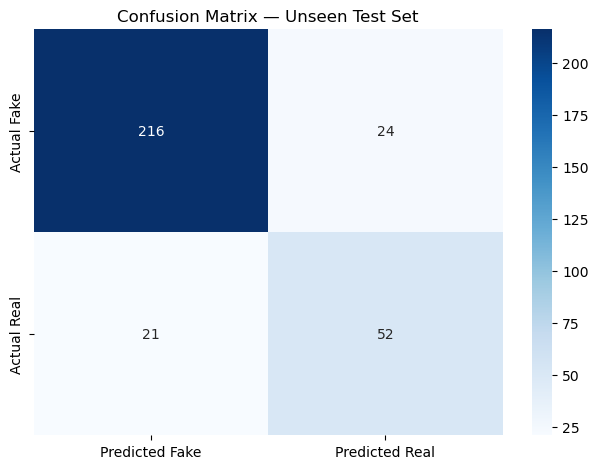

In [12]:
# Recreate the test generator with no augmentation and deterministic order.
_, _, test_gen = make_generators(batch_size=BATCH_SIZE, use_augmentation=False)
model = tf.keras.models.load_model(BEST_MODEL_PATH)

test_gen.reset()
prob_label1 = model.predict(test_gen, verbose=0).ravel()
y_true = test_gen.classes
y_pred = (prob_label1 >= 0.5).astype(int)

p_fake = (1 - prob_label1) if fake_label == 0 else prob_label1
y_fake = (y_true == fake_label).astype(int)
pred_fake = (p_fake >= 0.5).astype(int)

print("Class mapping:", test_gen.class_indices)
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro-F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Test Fake-class F1:", round(f1_score(y_fake, pred_fake, zero_division=0), 4))
print("Test Fake-class precision:", round(precision_score(y_fake, pred_fake, zero_division=0), 4))
print("Test Fake-class recall:", round(recall_score(y_fake, pred_fake, zero_division=0), 4))
try:
    print("Test Fake-class ROC-AUC:", round(roc_auc_score(y_fake, p_fake), 4))
except ValueError:
    print("Test Fake-class ROC-AUC could not be computed because the test set has only one class.")

print("\nClassification report (labels in folder-index order):")
print(classification_report(
    y_true, y_pred,
    labels=[fake_label, real_label],
    target_names=["Fake", "Real"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[fake_label, real_label])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Fake", "Predicted Real"],
    yticklabels=["Actual Fake", "Actual Real"]
)
plt.title("Confusion Matrix — Unseen Test Set")
plt.tight_layout()
plt.show()

### Test Results

The selected model achieved 85.62% test accuracy and a macro-F1 score of 0.8018. The Fake-class F1-score was 0.9057, with precision of 0.9114 and recall of 0.9000. The Real-class F1-score was approximately 0.70, with recall of 0.71. The Fake-class ROC-AUC score was 0.9003.

The model performed better on Fake images than on Real images. This means that some Real images were incorrectly classified, so the model does not perform equally well for both classes.

Another important finding is the difference between validation and test performance. E04 achieved a validation macro-F1 score of 1.000, but the selected model achieved a test macro-F1 score of 0.8018. The reason for this difference has not been confirmed. Differences in image characteristics, limited dataset size, or overlap between related images are possible factors that need further investigation.

## 7. Final Discussion

This project tested MobileNetV2 for classifying face images as Fake or Real. Ten configurations were compared, and E04 was selected based on validation macro-F1. However, the test results were lower than the validation results, showing that further improvement is needed.

**Explainability:** The model learns visual patterns automatically, but this project does not include an explainability method such as Grad-CAM. Therefore, it is not yet clear which image regions influence its predictions. Adding visual explanations would help investigate the model's decisions.

**Business recommendation:** The model could be considered for an initial attendance-system prototype, but it should not be used as the only security check. Further testing with new people, different lighting conditions, and different spoofing methods is needed. Its speed and performance on mobile devices should also be tested before practical use. An additional security check or human review should be available when predictions are uncertain.

**Limitations and future work:** The current model classifies images; it does not verify identity or perform complete video-based liveness detection. Subject overlap and near-duplicate images across the dataset splits also need to be checked. Future work should investigate these issues, improve performance on Real images, test the model on independent data, and measure its mobile performance.

Overall, the project shows that MobileNetV2 can be used for an initial face anti-spoofing experiment. However, the current results are not enough to confirm that it is reliable for real attendance systems.

In [14]:

# ==========================================
# Export trained model to TensorFlow Lite
# ==========================================

import tensorflow as tf
import os

# 1. Load the selected, trained model
model_path = BEST_MODEL_PATH
model = tf.keras.models.load_model(model_path)

print("Model loaded:", model_path)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

# 2. Convert the Keras model to TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# 3. Save the converted model
tflite_path = "face_liveness_model.tflite"

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

# 4. Confirm the exported file
print("Export completed:", os.path.abspath(tflite_path))
print("File size:", round(os.path.getsize(tflite_path) / 1024, 2), "KB")

# 5. Verify that TensorFlow Lite can load the model
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

print("TFLite input:", interpreter.get_input_details()[0]["shape"])
print("TFLite output:", interpreter.get_output_details()[0]["shape"])
print("TFLite model verification successful.")


Model loaded: best_liveness_model.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
INFO:tensorflow:Assets written to: C:\Users\DELL\AppData\Local\Temp\tmpk79fhbei\assets


INFO:tensorflow:Assets written to: C:\Users\DELL\AppData\Local\Temp\tmpk79fhbei\assets


Saved artifact at 'C:\Users\DELL\AppData\Local\Temp\tmpk79fhbei'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2399146185488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146185680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146184720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146187024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146185872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146185296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146183760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146183568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146196816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146185104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2399146

c:\Users\DELL\anaconda3\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [15]:
import tensorflow as tf
import numpy as np

# Load the Keras model
keras_model = tf.keras.models.load_model(
    "best_liveness_model.keras"
)

# Load the TensorFlow Lite model
interpreter = tf.lite.Interpreter(
    model_path="face_liveness_model.tflite"
)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:", input_details)
print("Output details:", output_details)

# Create a sample input image tensor
sample_image = np.random.rand(
    1, 224, 224, 3
).astype(np.float32)

# Predict using Keras
keras_prediction = keras_model.predict(
    sample_image, verbose=0
)

# Predict using TensorFlow Lite
interpreter.set_tensor(
    input_details[0]["index"],
    sample_image
)
interpreter.invoke()

tflite_prediction = interpreter.get_tensor(
    output_details[0]["index"]
)

print("Keras prediction:", keras_prediction)
print("TFLite prediction:", tflite_prediction)

print(
    "Predictions match:",
    np.allclose(
        keras_prediction,
        tflite_prediction,
        atol=1e-4
    )
)

Input details: [{'name': 'serving_default_input_layer:0', 'index': 0, 'shape': array([  1, 224, 224,   3], dtype=int32), 'shape_signature': array([ -1, 224, 224,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]
Output details: [{'name': 'StatefulPartitionedCall_1:0', 'index': 175, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]
Keras prediction: [[0.0024283]]
TFLite prediction: [[0.00242836]]
Predictions match: True
